# Precio de la vivienda e ingresos en España

Primero vemos cómo cambia el precio desde 2000 y si los ingresos siguen ese ritmo. Después estudiamos el ciclo y las diferencias territoriales. El histórico largo y las presidencias aportan contexto; la cobertura y los supuestos cierran el análisis.

Tasación no equivale a precio de compraventa. El salario neto es el de un perfil fiscal; la remuneración histórica incluye cotizaciones empresariales.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

ROOT = Path.cwd()
if not (ROOT / "data/snapshots/block01").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
from spain_housing.prices_analysis import load_purchase_data, run_analysis, series_for

values, municipal, cpi, governments = load_purchase_data(ROOT)
purchase = series_for(values, level="national")
FIGURES = ROOT / "reports/figures/block01"
TABLES = ROOT / "reports/tables/block01"
def show(*names):
    for name in names:
        display(Image(filename=str(FIGURES / f"{name}.png")))

# Regenerar una sola vez todos los entregables del bloque.
figures, findings = run_analysis(ROOT)

## Evolución nacional

El código muestra directamente la serie utilizada.

In [2]:
# Observaciones originales de tasación: una sola medida, sin encadenar otras fuentes.
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(purchase.index, purchase, color="#207b8e", linewidth=2.5)
ax.set(title="Compra: tasación nacional de vivienda libre, 2000–2025", ylabel="€/m²", xlabel="Año")
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
display(fig)
plt.close(fig)


<Figure size 1200x500 with 1 Axes>

## Salario neto y valor de la vivienda

Dos gráficas separadas: **salario neto anual** y **valor de una vivienda de referencia de 80 m²**. Ambas muestran importes en euros corrientes y el mismo periodo, **2000–2023**. Cada una indica el importe inicial, el final y la subida total.

El valor de la vivienda es tasación nacional MIVAU × 80 m². El salario neto procede de [Eurostat, earn_nt_net](https://ec.europa.eu/eurostat/databrowser/view/earn_nt_net/default/table?lang=en): persona soltera sin hijos al 100 % del salario de referencia. No es el neto medio observado de todos los españoles.

Se mantiene 2023 como final por los datos salariales anómalos y la ruptura de 2024. La primera gráfica de precios del notebook llega a 2025; aquí los dos conceptos se comparan hasta 2023.


In [3]:
from spain_housing.salary_analysis import load_salary_comparison, variation_gaps

salary_panel, salary_nominal, salary_real = load_salary_comparison(ROOT, purchase, cpi)
salary_variation_gap = variation_gaps(salary_nominal)

Las dos gráficas usan ejes desde cero y muestran las cantidades. Sus escalas son diferentes porque una vivienda cuesta mucho más que un salario anual; para comparar el crecimiento utilizamos los porcentajes del apartado siguiente.

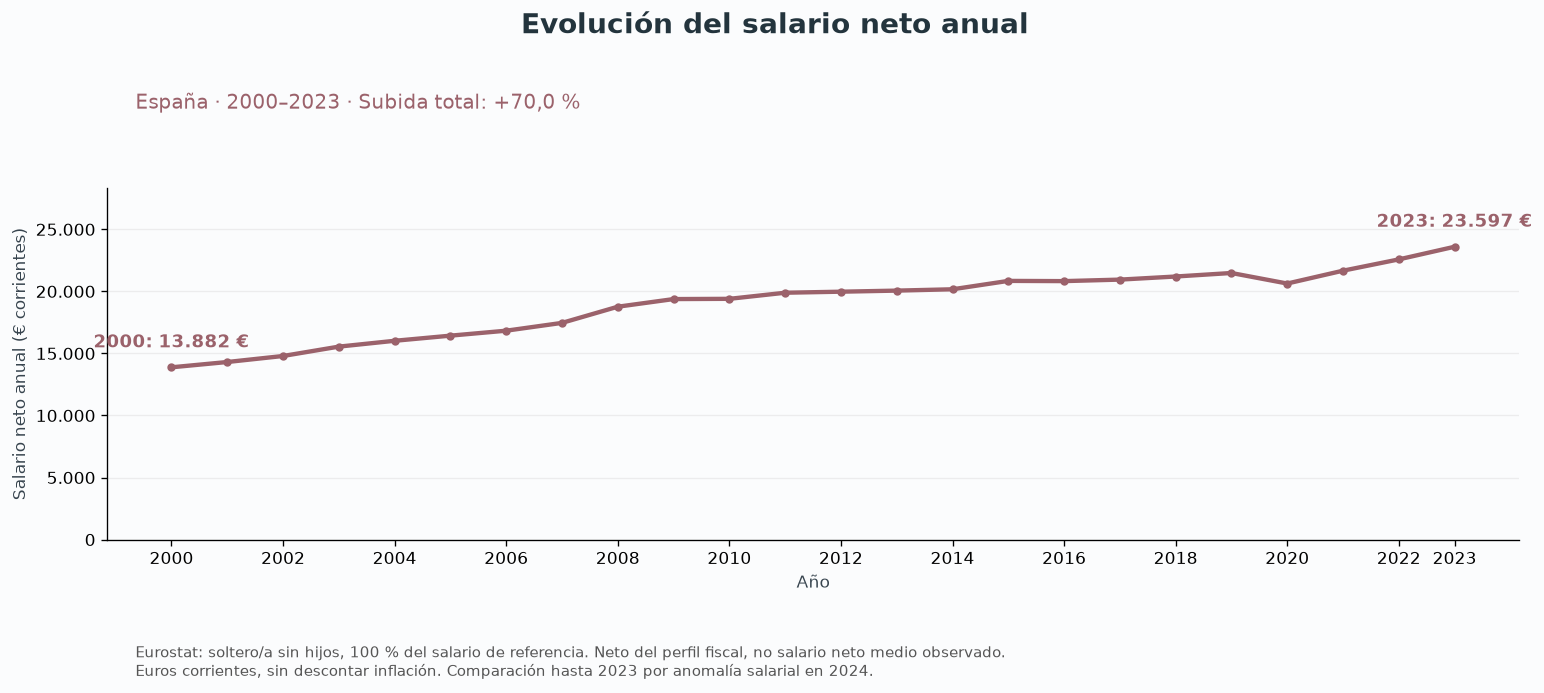

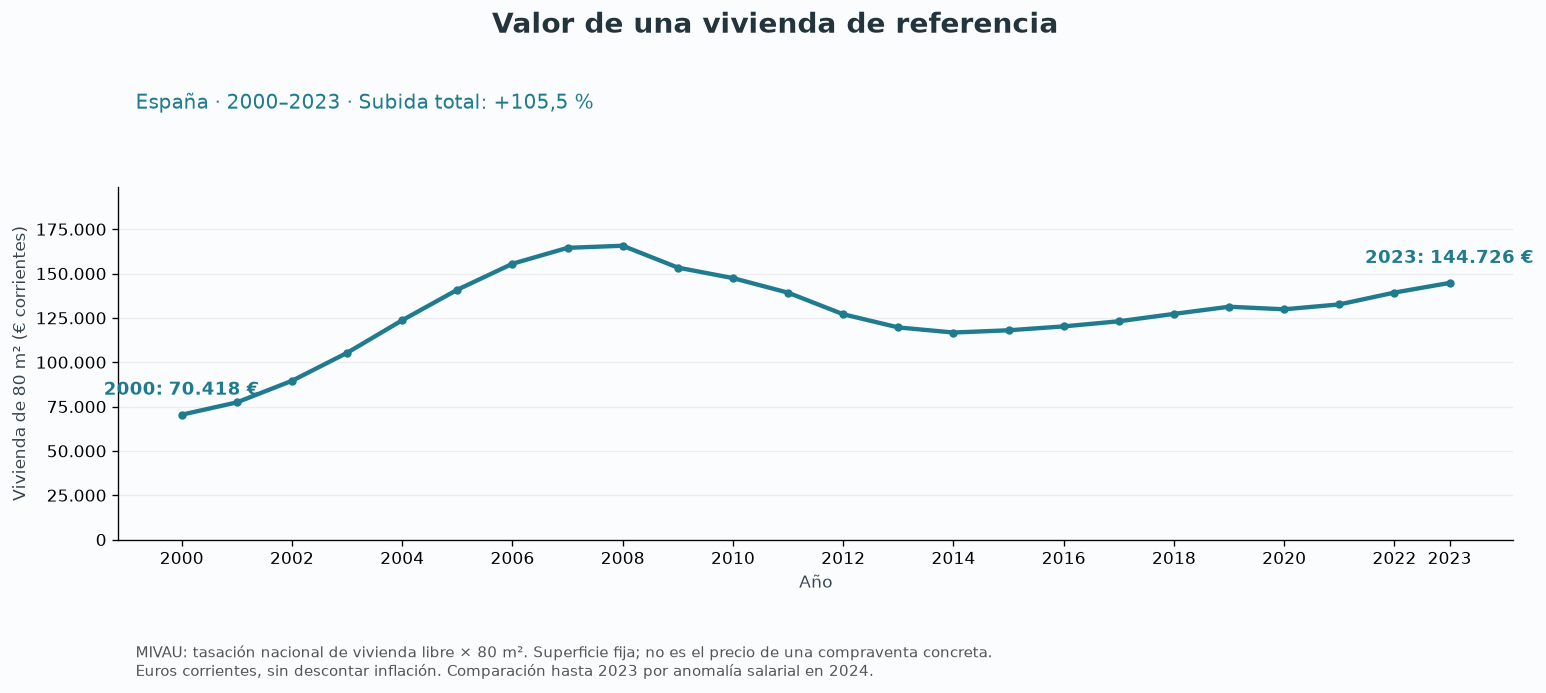

In [4]:
show("20_net_salary_history", "21_housing_value_history")

### Subida total de la vivienda y del salario neto

La siguiente gráfica compara **cuánto ha subido cada importe entre 2000 y 2023**: `(importe de 2023 / importe de 2000 - 1) × 100`.

Son porcentajes acumulados nominales, sin descontar inflación. No son tasas anuales ni se obtienen sumando las subidas de cada año. Tampoco son por sí solos una medida completa de accesibilidad a la vivienda.

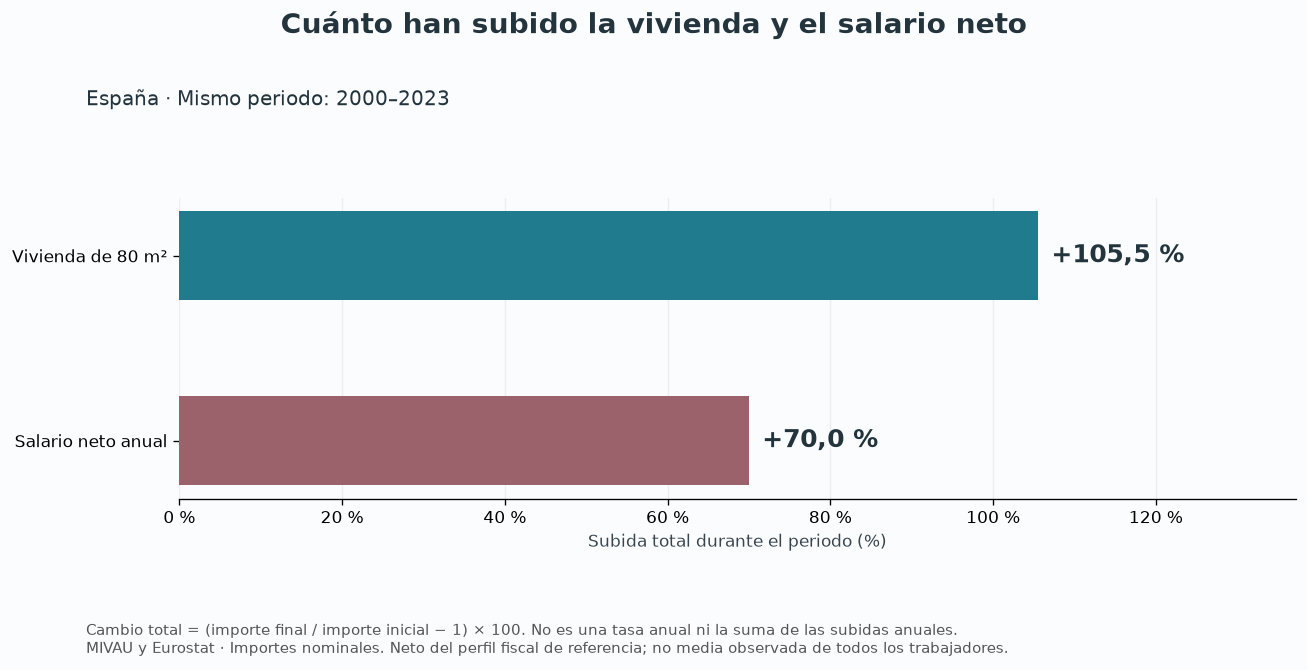

In [5]:
show("22_housing_net_salary_total_change")

## Compra frente a los precios generales

Comparamos cuánto ha subido la compra respecto a los precios generales, medidos por el IPC. El IPC no indica si los ingresos han crecido al mismo ritmo.

In [6]:
# La comparación empieza donde hay datos de ambas series: 2002.
years = sorted(set(purchase.index) & set(cpi.index))
base = years[0]
comparison = pd.DataFrame({
    "Compra: tasación €/m²": purchase.loc[years] / purchase.loc[base] * 100,
    "Precios generales (IPC)": cpi.loc[years] / cpi.loc[base] * 100,
})
display((comparison.iloc[-1] - 100).to_frame("Cambio acumulado (%)").round(2))
fig, ax = plt.subplots(figsize=(12, 5))
comparison.plot(ax=ax)
ax.set(title=f"Compra frente a precios generales, {years[0]}–{years[-1]}", ylabel=f"{base} = 100", xlabel="Año")
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
display(fig)
plt.close(fig)


,Cambio acumulado (%)
Compra: tasación €/m²,90.11
Precios generales (IPC),66.57


<Figure size 1200x500 with 1 Axes>

## Cambios anuales y ciclo

Extremos: máximo 2000–2008 y mínimo 2009–2015.

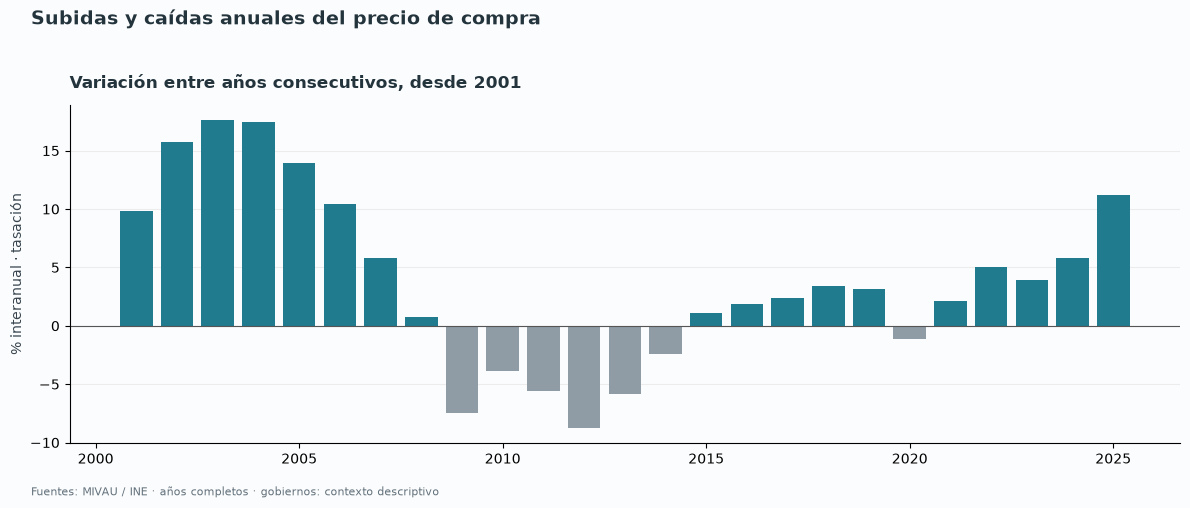

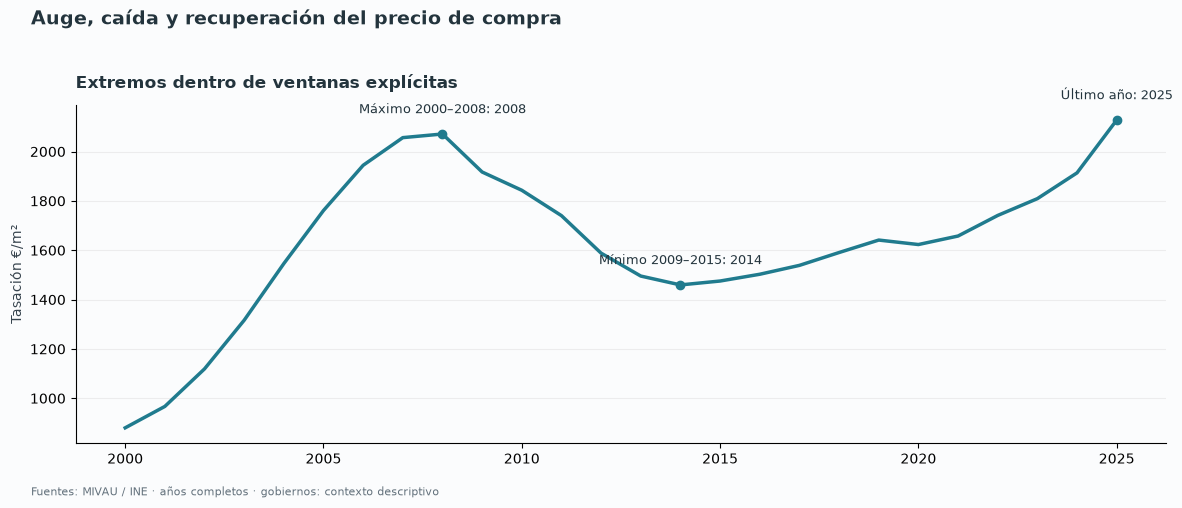

In [7]:
show("04_annual_changes", "05_purchase_cycle")

## Comunidades y provincias

Nivel 2025 y cambio 2000–2025 con extremos fijos. Las tablas mantienen años ausentes y cobertura.

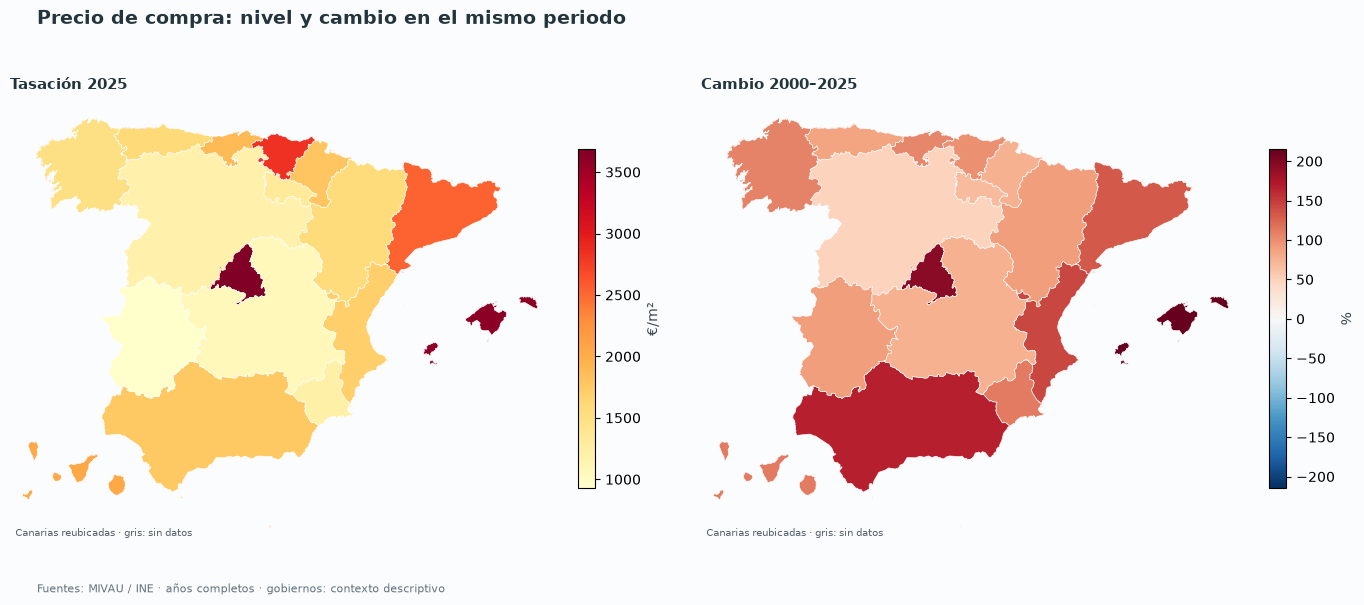

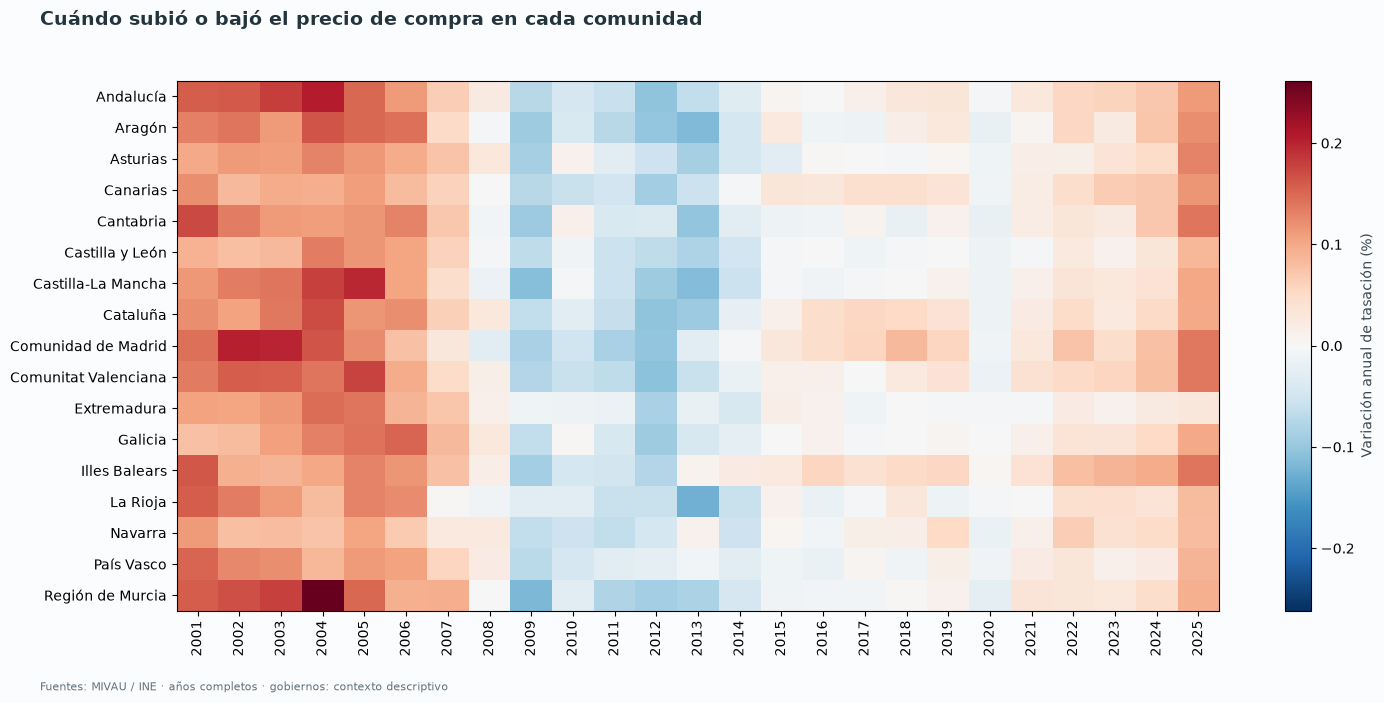

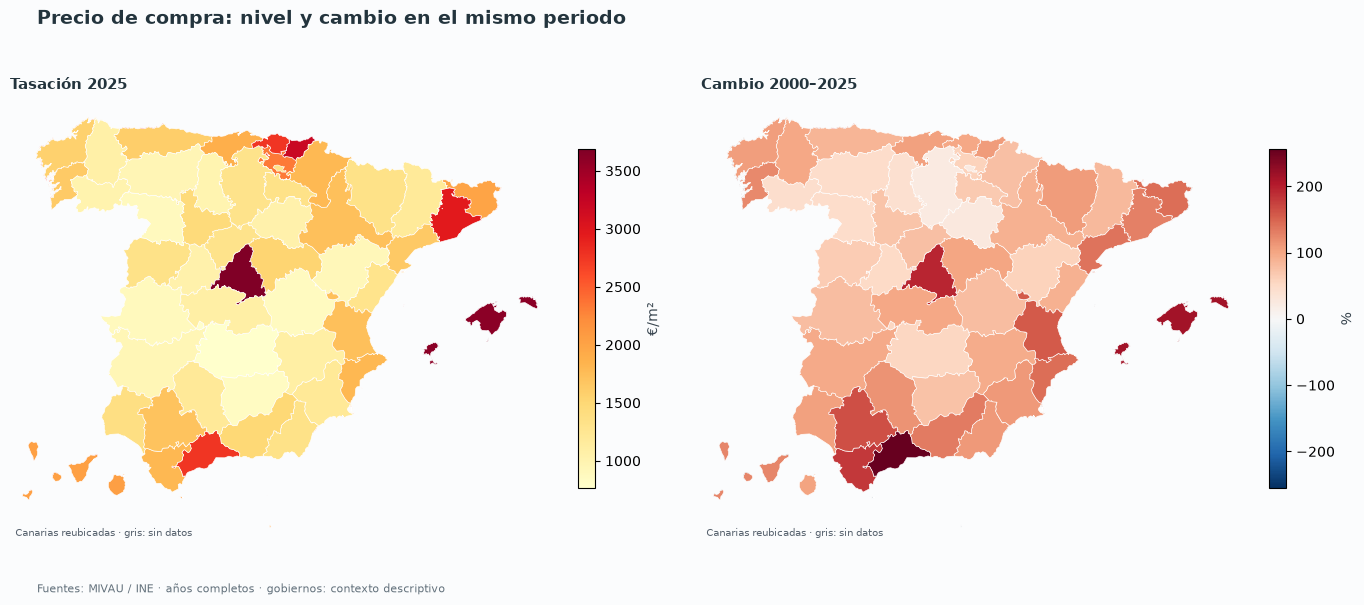

In [8]:
show("07_regional_maps", "08_regional_heatmap", "12_provincial_maps")

## Municipios y perfiles

30 casos desde 2005; muestras fijas, medias no ponderadas. La selección no representa todos los municipios españoles.

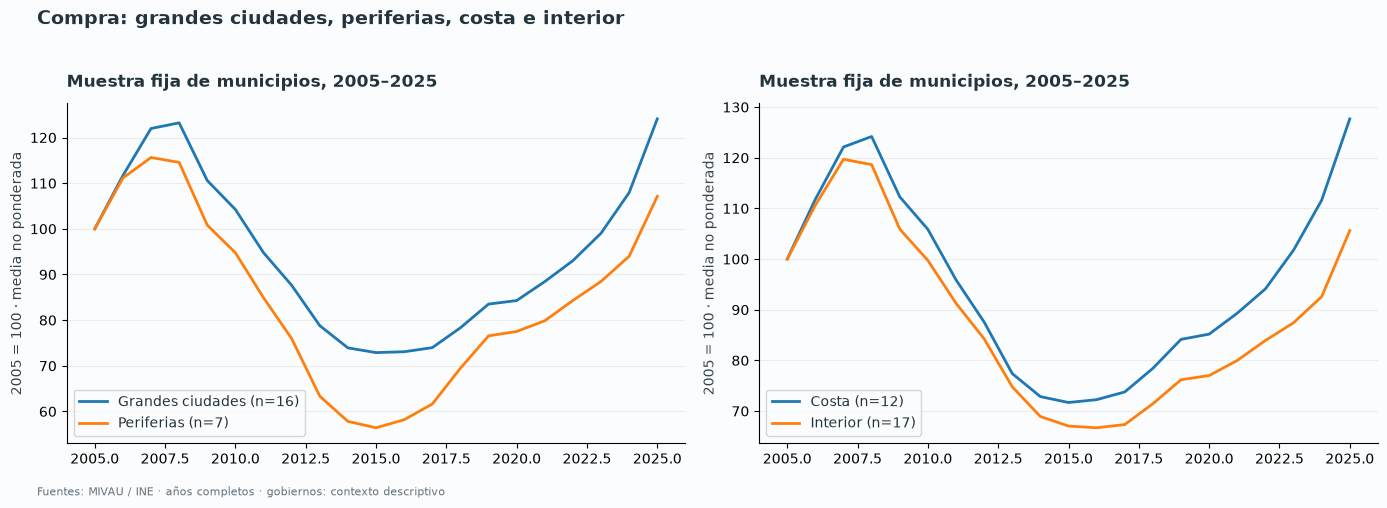

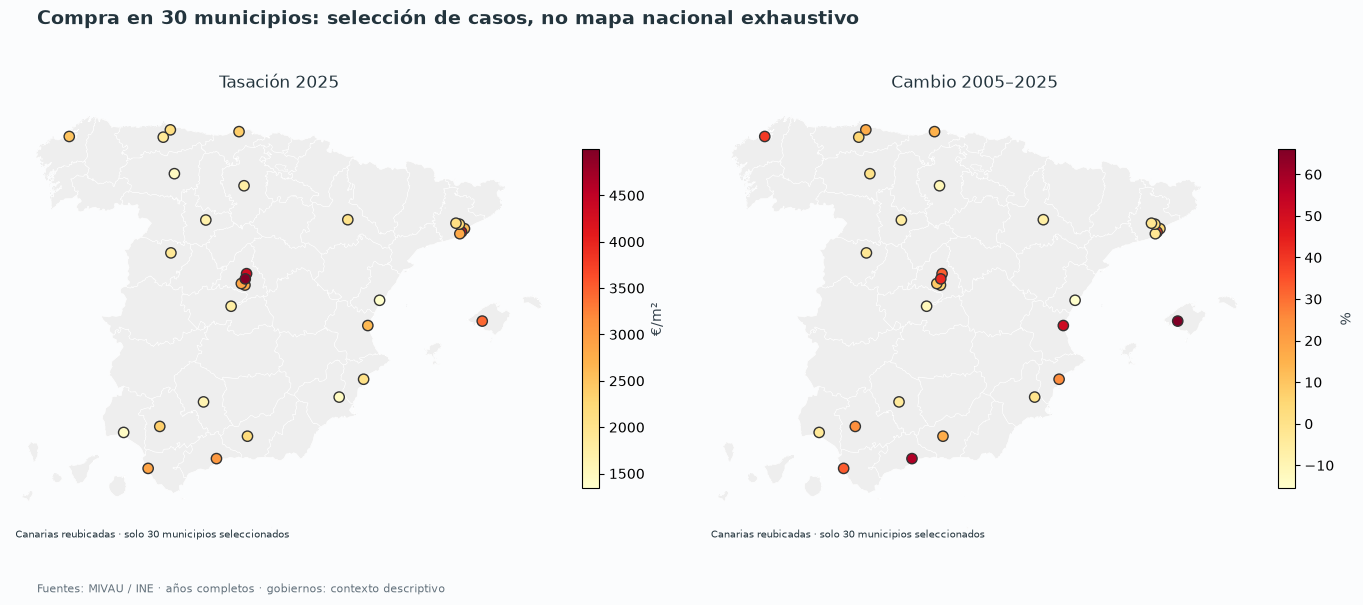

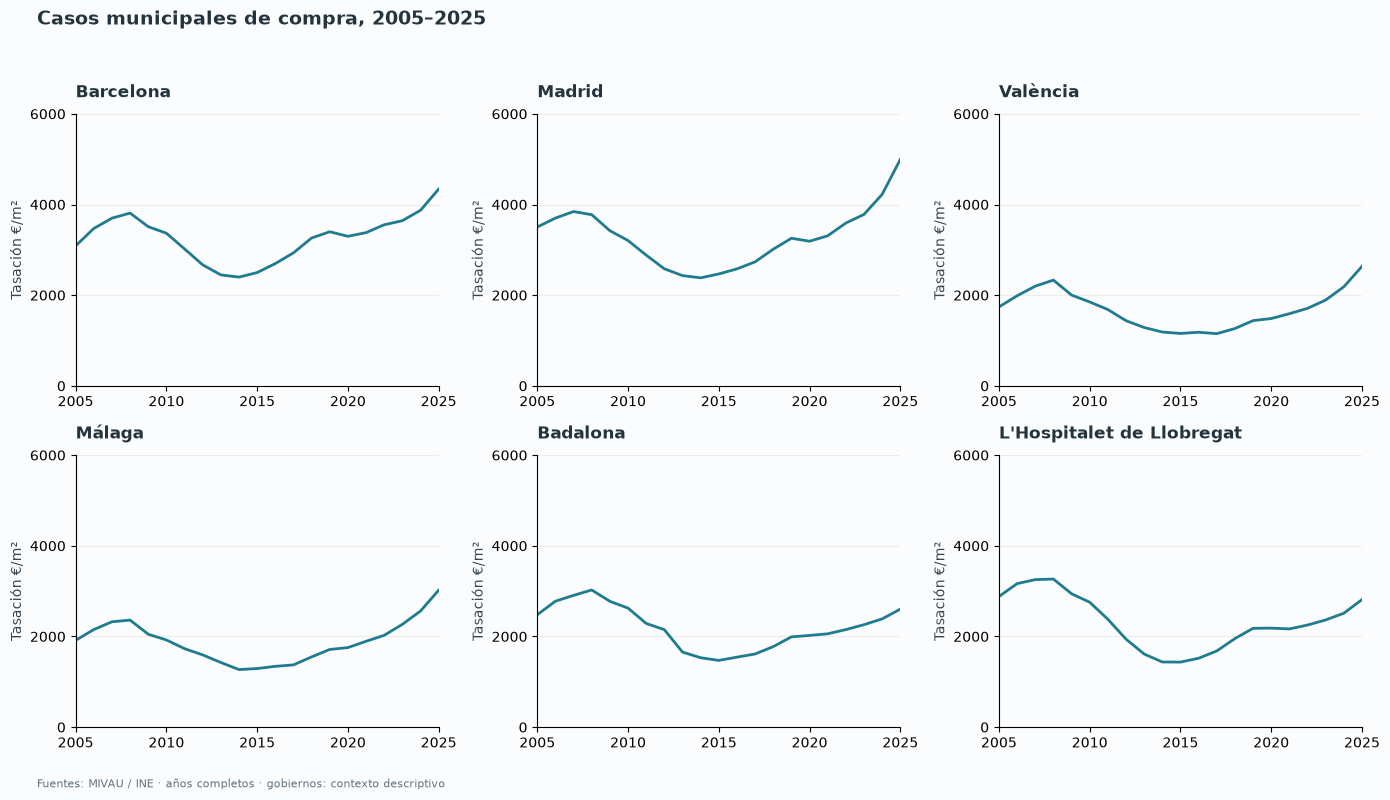

,code,name,year,value,growth_pct,urban_category,coastal_category
0,3014,Alacant/Alicante,2025,2069.35,25.38,large_city,coastal
1,7040,Palma,2025,3424.15,65.98,large_city,coastal
2,8015,Badalona,2025,2603.70,5.01,periphery,coastal
3,8019,Barcelona,2025,4339.92,40.59,large_city,coastal
4,8101,L'Hospitalet de Llobregat,2025,2812.72,-2.33,periphery,unclassified
5,8187,Sabadell,2025,2254.82,2.73,periphery,inland
6,8279,Terrassa,2025,2099.10,-1.78,periphery,inland
7,9059,Burgos,2025,1755.25,-10.57,selected_city,inland
8,11012,Cádiz,2025,2885.02,33.35,selected_city,coastal
9,12040,Castelló de la Plana/Castellón de la Plana,2025,1338.72,-15.58,selected_city,coastal


In [9]:
show("06_territorial_profiles", "13_municipal_maps", "15_municipal_cases")
display(pd.read_csv(TABLES / "selected_municipalities.csv").round(2))

## Muestras municipales fijas

La composición está publicada para evitar que cambie el conjunto de municipios que aporta a cada media.

In [10]:
samples = pd.read_csv(TABLES / "profile_fixed_samples.csv", dtype={"code": str})
display(samples.groupby(["category", "group"]).agg(municipalities=("code", "nunique"), first_year=("first_year", "min"), last_year=("last_year", "max")))

municipalities  first_year  last_year
category         group                                            
coastal_category coastal                 12        2005       2025
                 inland                  17        2005       2025
urban_category   large_city              16        2005       2025
                 periphery                7        2005       2025

## Comparación histórica de vivienda y remuneración

La cobertura común disponible es **1971–2025: 54 años entre extremos**, con 55 observaciones anuales. No hay datos para completar los 60 años pedidos con estas fuentes; no extrapolamos esos años.

Se mantiene la comparación anterior de salario neto. Aquí utilizamos **remuneración anual por asalariado (AMECO)**: incluye salario bruto y cotizaciones a cargo de la empresa, por lo que **no equivale al dinero que cobra el trabajador**. Los importes anteriores al euro se convierten a euros al tipo fijo de la peseta, sin introducir variaciones del tipo de cambio.

La vivienda se muestra en **euros corrientes para una superficie fija de 80 m²**, como en la comparación anterior. **Es una estimación histórica**, no un precio observado de compraventa: `tasación MIVAU 2025 por m² × 80 × (índice BIS del año / índice BIS 2025)`. Se aplica esta misma fórmula a todos los años para conservar una evolución coherente; los precios observados desde 2000 están en las gráficas anteriores. No se debe interpretar como el precio medio real pagado por una casa de 80 m² en 1971.

Se usan medias BIS de cuatro trimestres completos. 2026 incompleto y previsiones AMECO quedan excluidos. Los porcentajes acumulados no cambian al convertir el índice a una referencia en euros.

**La serie de vivienda cambia de cobertura y metodología:** 1971–1974, estadísticas históricas OCDE; 1975–1986, precios del área de Madrid; 1987–2006, precios nacionales por m²; desde 2007, índice nacional basado en INE. El tramo de Madrid aparece sombreado. Este histórico ofrece contexto, pero no es una medida nacional homogénea durante todo el periodo.

Fuentes: [BIS, serie nominal de España](https://data.bis.org/topics/RPP/BIS,WS_SPP,1.0/Q.ES.N.628), [metodología BIS](https://www.bis.org/statistics/pp_selected_documentation.pdf), [Comisión Europea, AMECO](https://economy-finance.ec.europa.eu/economic-research-and-databases/economic-databases/ameco-database/download-annual-data-set-macro-economic-database-ameco_en).


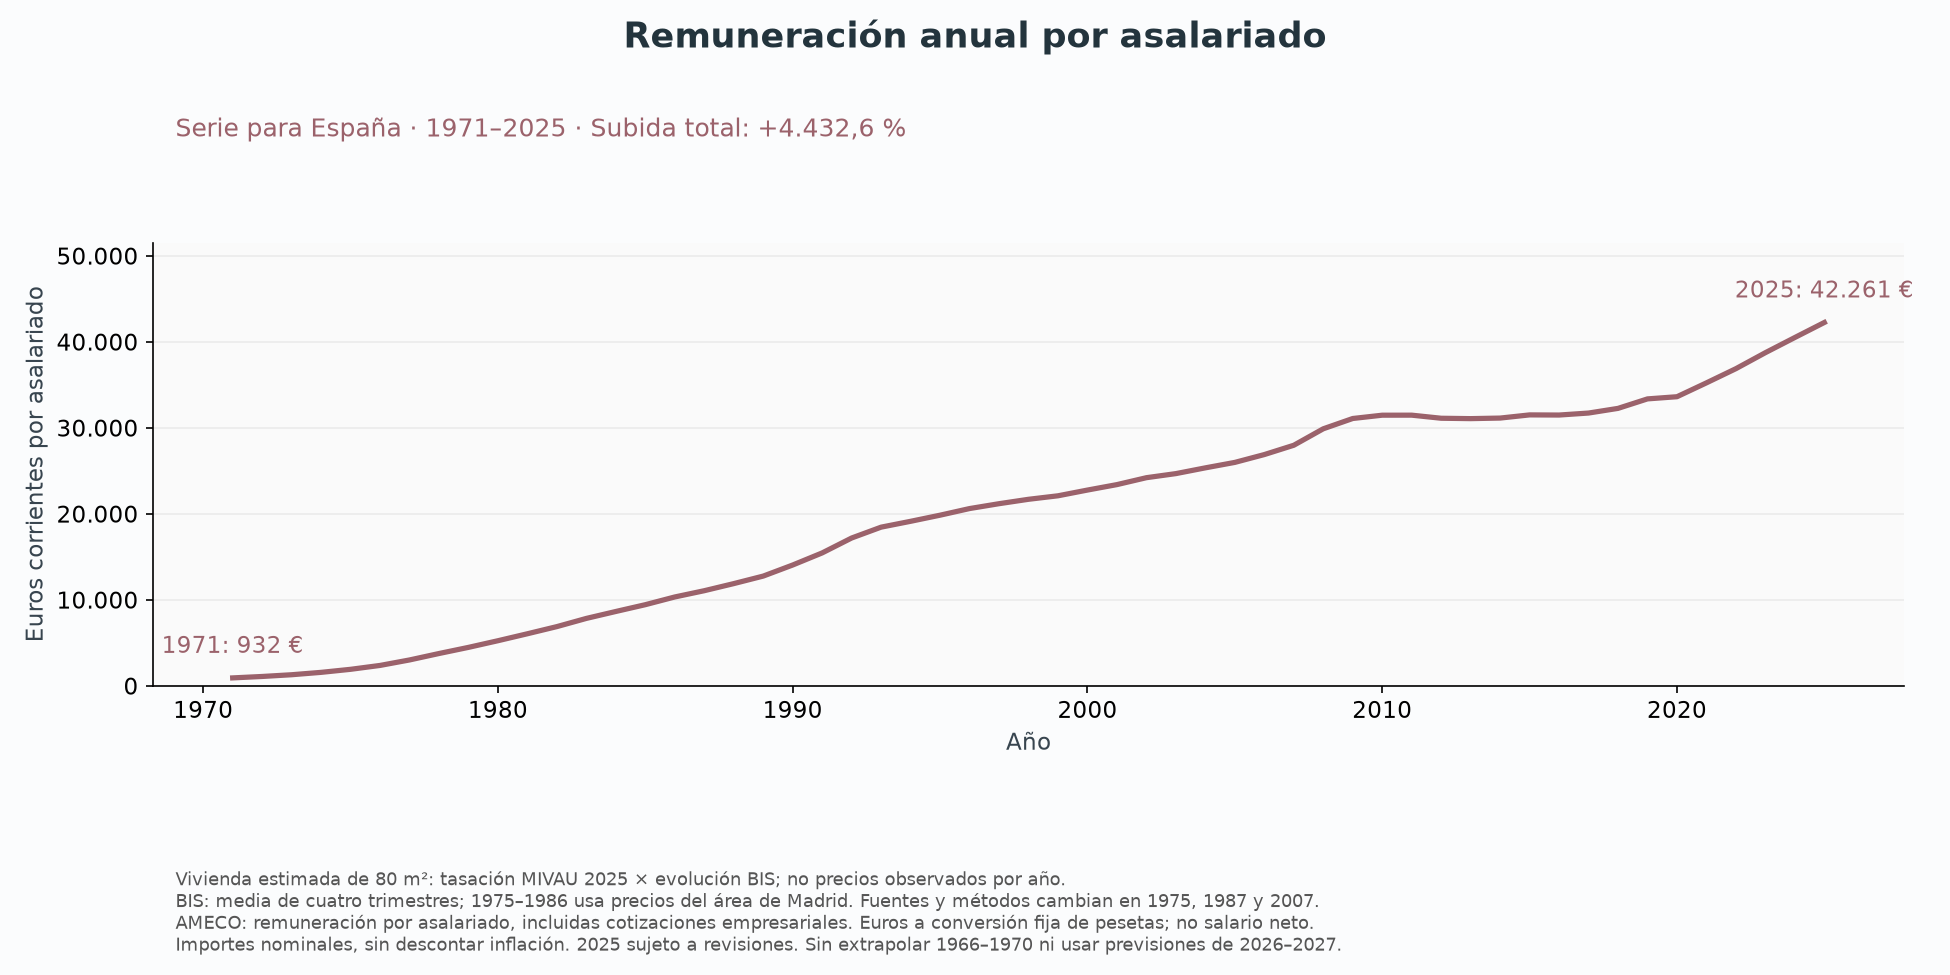

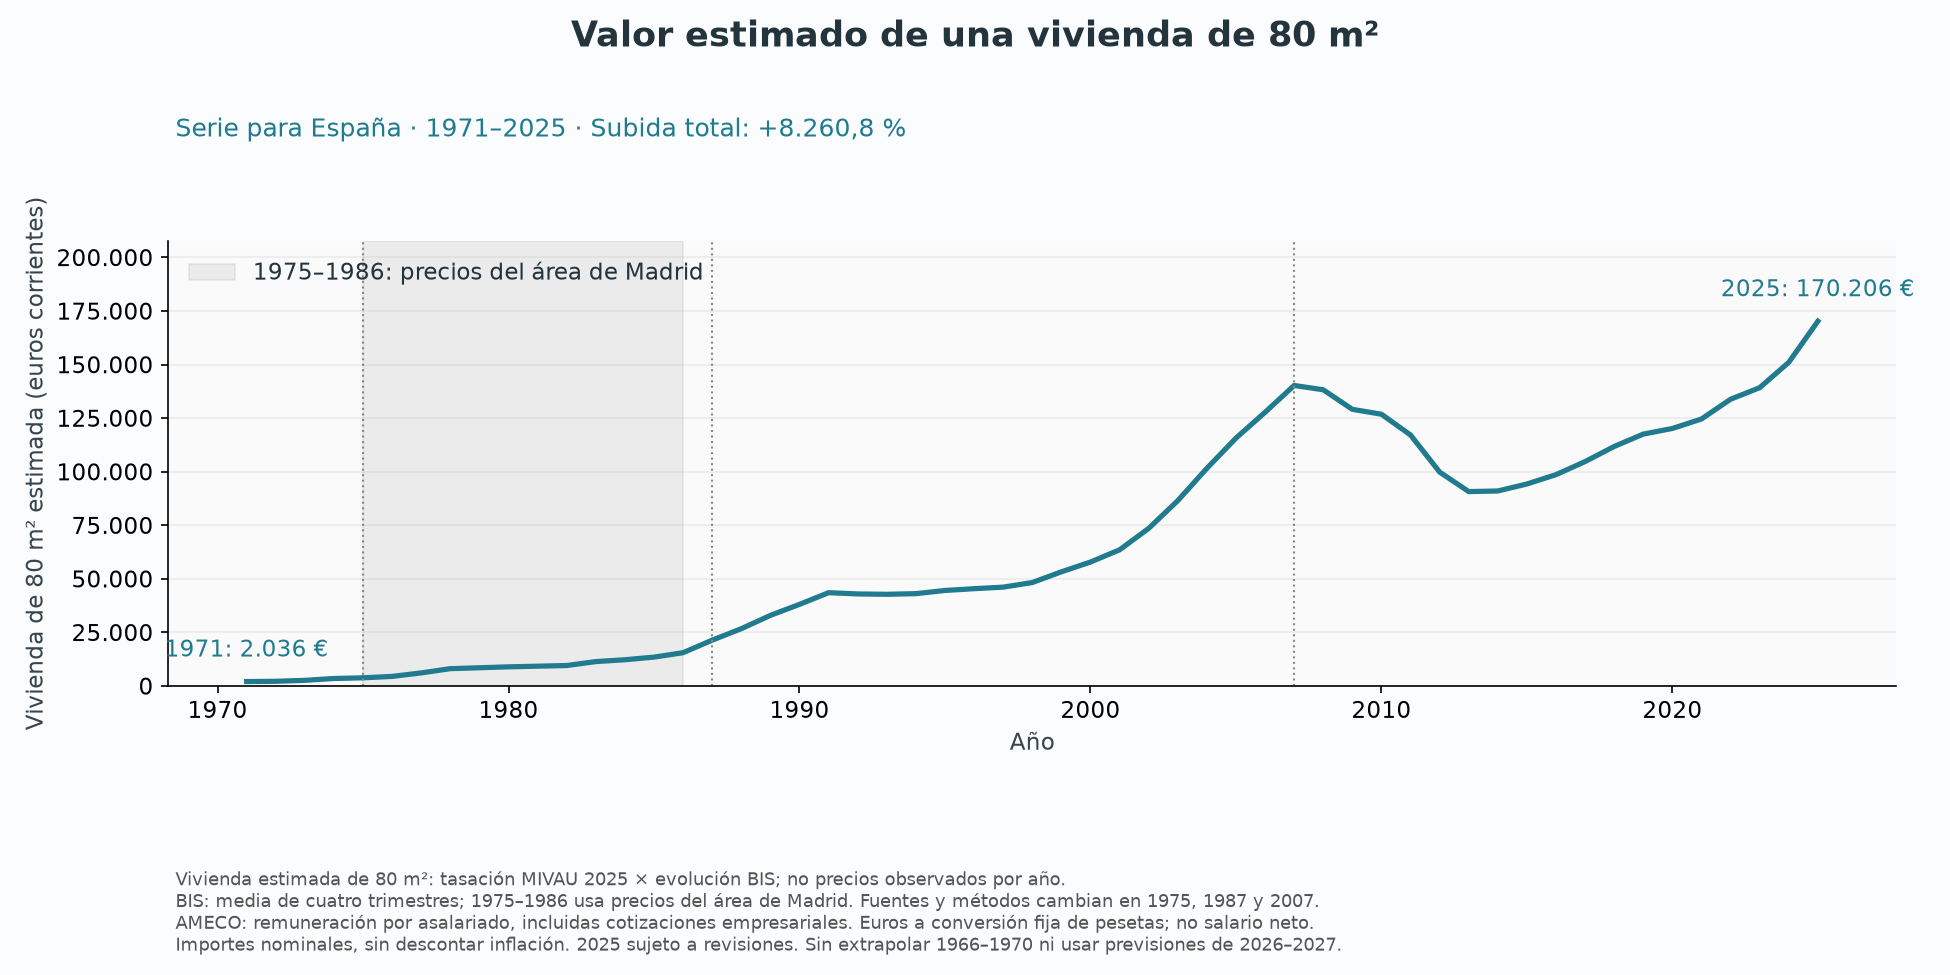

In [11]:
show("23_long_compensation_history", "24_long_housing_history")

### Subida total durante el periodo histórico

Ambas barras utilizan **1971–2025** y la misma fórmula: `(valor final / valor inicial - 1) × 100`. Los cambios son nominales, sin descontar inflación. El indicador salarial incluye cotizaciones empresariales. La diferencia entre barras no demuestra una causa ni mide directamente la accesibilidad a la vivienda.

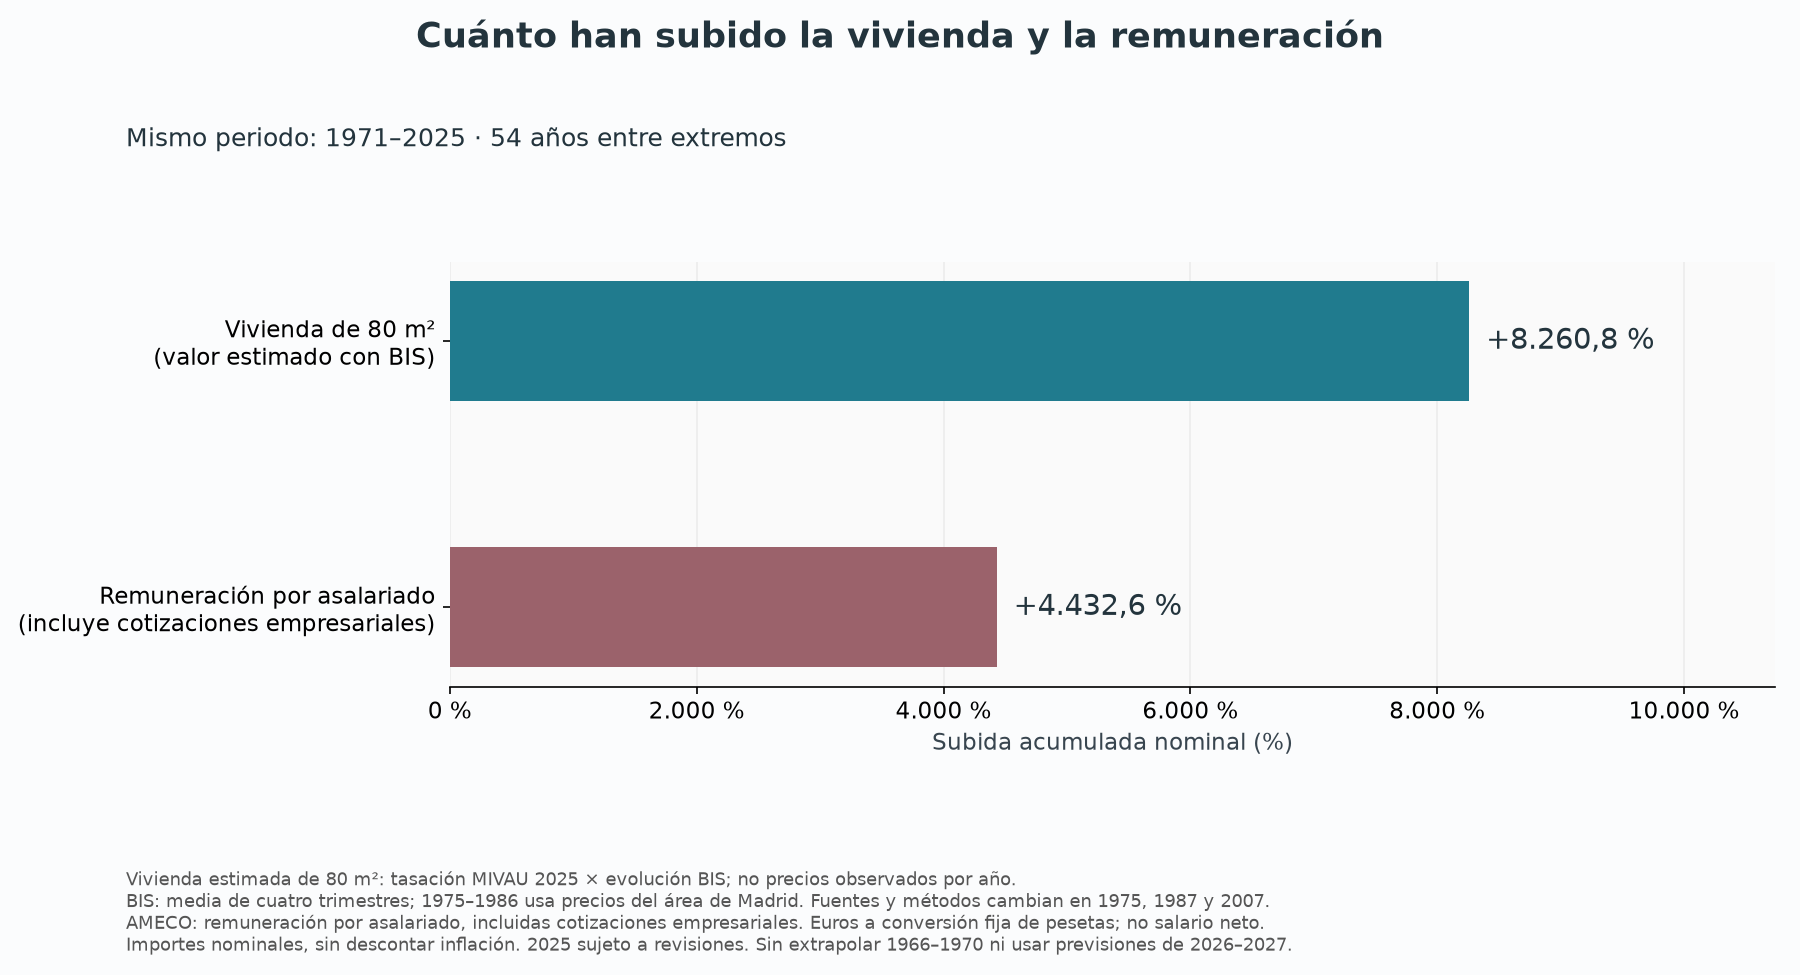

In [12]:
show("25_long_housing_compensation_change")

## Gobiernos como contexto temporal

Franjas de presidencias, sin atribución causal. Los periodos observados usan años completos dentro de cada mandato; no son un ranking de partidos.

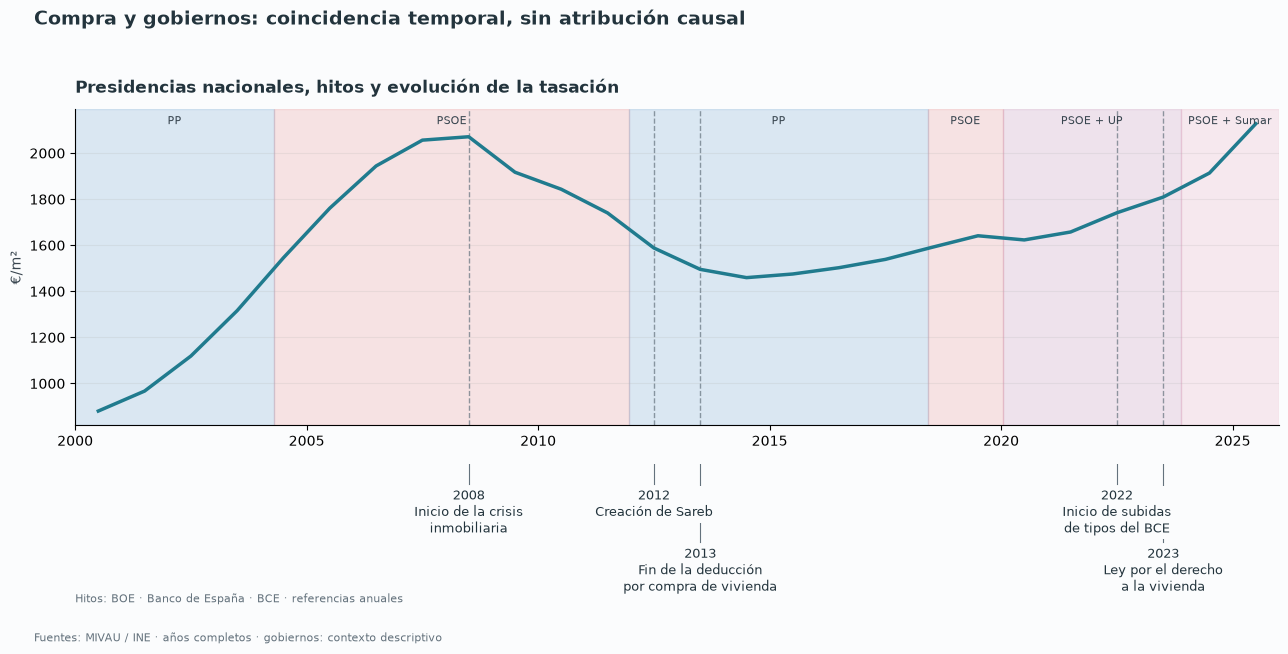

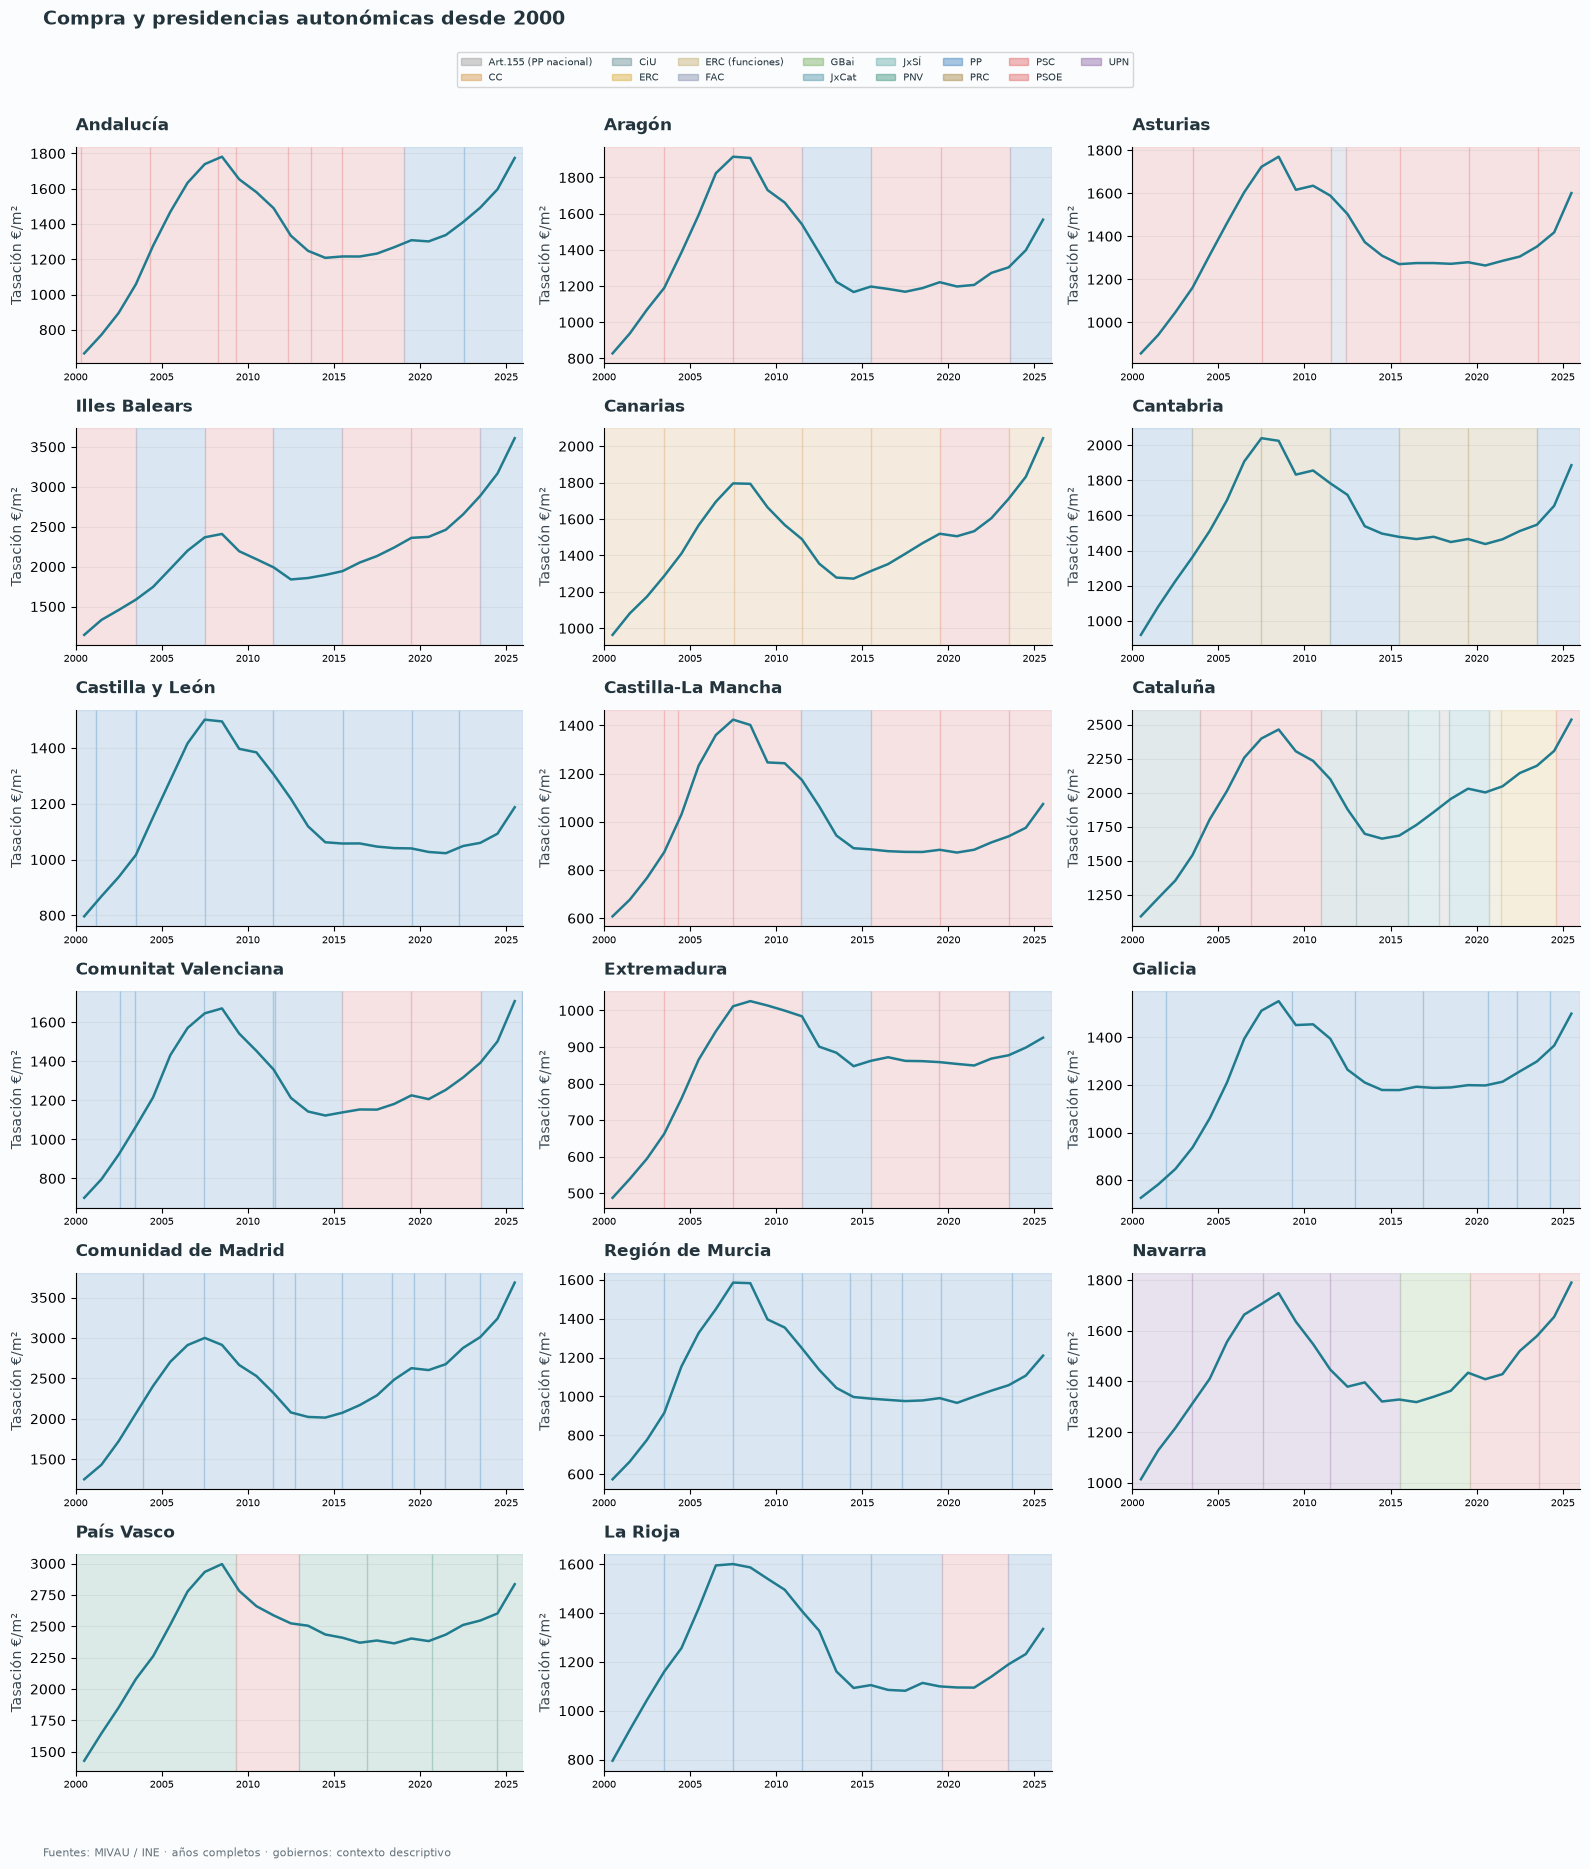

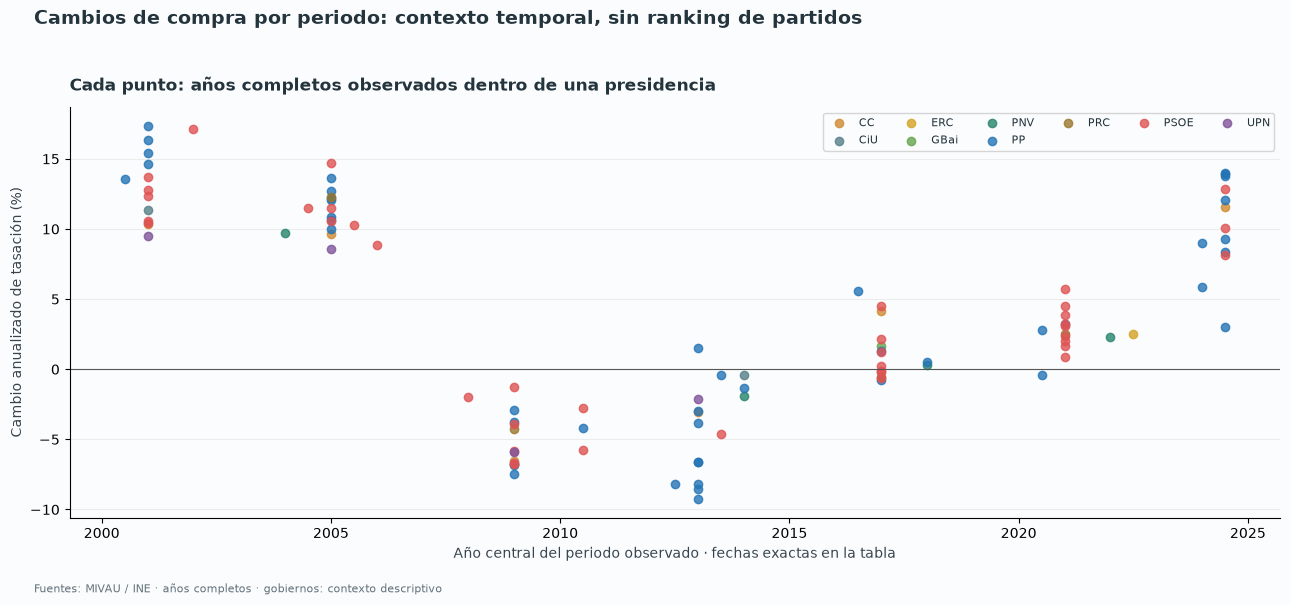

In [13]:
show("02_national_governments", "09_regional_governments_purchase", "10_mandate_comparison")

## Presidencias y años completos

Excluimos los años de transición. Las ventanas tienen duraciones y contextos distintos; una coincidencia no identifica efectos de políticas.

In [14]:
mandates = pd.read_csv(TABLES / "government_history.csv", dtype={"code": str})
display(mandates[mandates.code == "00"].round(2))
display(mandates[mandates.code != "00"].round(2))

,metric,code,name,leader,party,start,end,observed_complete_years,first_year,last_year,nominal_change_pct,annualised_pct,real_change_pct
0,purchase_valuation,00,España,José María Aznar,PP,1996-05-04,2004-04-17,4,2000.0,2003.0,49.54,14.35,NaN
1,purchase_valuation,00,España,José Luis Rodríguez Zapatero,PSOE,2004-04-17,2011-12-21,6,2005.0,2010.0,4.66,0.91,-6.89
2,purchase_valuation,00,España,Mariano Rajoy,PP,2011-12-21,2018-06-02,6,2012.0,2017.0,-3.12,-0.63,-5.49
3,purchase_valuation,00,España,Pedro Sánchez,PSOE,2018-06-02,2020-01-13,1,NaN,NaN,NaN,NaN,NaN
4,purchase_valuation,00,España,Pedro Sánchez,PSOE + UP,2020-01-13,2023-11-21,2,2021.0,2022.0,5.03,5.03,-3.10
5,purchase_valuation,00,España,Pedro Sánchez,PSOE + Sumar,2023-11-21,NaN,2,2024.0,2025.0,11.18,11.18,8.29


,metric,code,name,leader,party,start,end,observed_complete_years,first_year,last_year,nominal_change_pct,annualised_pct,real_change_pct
6,purchase_valuation,16,País Vasco,José Antonio Ardanza Garro (PNV),PNV,1994-12-30,2009-05-06,9,2000.0,2008.0,109.67,9.70,NaN
7,purchase_valuation,16,País Vasco,Francisco Javier López Álvarez (PSOE),PSOE,2009-05-06,2012-12-14,2,2010.0,2011.0,-2.76,-2.76,-5.78
8,purchase_valuation,16,País Vasco,Iñigo Urkullu Rentería (PNV),PNV,2012-12-14,2016-11-25,3,2013.0,2015.0,-3.82,-1.93,-3.19
9,purchase_valuation,16,País Vasco,Iñigo Urkullu Rentería (PNV),PNV,2016-11-25,2020-09-03,3,2017.0,2019.0,0.67,0.33,-1.68
10,purchase_valuation,16,País Vasco,Iñigo Urkullu Rentería (PNV),PNV,2020-09-03,2024-06-21,3,2021.0,2023.0,4.60,2.28,-6.79
...,...,...,...,...,...,...,...,...,...,...,...,...,...
124,purchase_valuation,07,Castilla y León,Juan Vicente Herrera Campo (PP),PP,2007-06-28,2011-06-24,3,2008.0,2010.0,-7.41,-3.78,-8.79
125,purchase_valuation,07,Castilla y León,Juan Vicente Herrera Campo (PP),PP,2011-06-24,2015-07-03,3,2012.0,2014.0,-12.80,-6.62,-13.88
126,purchase_valuation,07,Castilla y León,Juan Vicente Herrera Campo (PP),PP,2015-07-03,2019-07-11,3,2016.0,2018.0,-1.59,-0.80,-5.07
127,purchase_valuation,07,Castilla y León,Alfonso Fernando Fernández Mañueco (PP),PP,2019-07-11,2022-04-12,2,2020.0,2021.0,-0.43,-0.43,-3.42


## Anexo: cobertura y detalles del cálculo

Las tablas siguientes permiten revisar los años observados, los huecos y los extremos del ciclo. No se sustituyen extremos ausentes por años cercanos.

In [15]:
for level in ["national", "region", "province", "municipal"]:
    table = pd.read_csv(TABLES / f"{level}_purchase_history.csv")
    print(level)
    display(table[["code", "name", "first_year", "last_year", "observed_years", "missing_years", "nominal_change_pct"]].round(2))

national


,code,name,first_year,last_year,observed_years,missing_years,nominal_change_pct
0,0,España,2000,2025,26,0,141.71


region


,code,name,first_year,last_year,observed_years,missing_years,nominal_change_pct
0,1,Andalucía,2000,2025,26,0,166.46
1,2,Aragón,2000,2025,26,0,89.28
2,3,Asturias,2000,2025,26,0,87.11
3,4,Illes Balears,2000,2025,26,0,215.08
4,5,Canarias,2000,2025,26,0,112.04
5,6,Cantabria,2000,2025,26,0,104.77
6,7,Castilla y León,2000,2025,26,0,49.09
7,8,Castilla-La Mancha,2000,2025,26,0,76.69
8,9,Cataluña,2000,2025,26,0,132.13
9,10,Comunitat Valenciana,2000,2025,26,0,143.66


province


,code,name,first_year,last_year,observed_years,missing_years,nominal_change_pct
0,1,Araba/Álava,2000,2025,26,0,58.36
1,2,Albacete,2000,2025,26,0,95.56
2,3,Alicante/Alacant,2000,2025,26,0,143.20
3,4,Almería,2000,2025,26,0,110.96
4,5,Ávila,2000,2025,26,0,50.51
5,6,Badajoz,2000,2025,26,0,96.12
6,7,"Balears, Illes",2000,2025,26,0,215.08
7,8,Barcelona,2000,2025,26,0,128.39
8,9,Burgos,2000,2025,26,0,22.53
9,10,Cáceres,2000,2025,26,0,79.54


municipal


,code,name,first_year,last_year,observed_years,missing_years,nominal_change_pct
0,3014,Alacant/Alicante,2005,2025,21,0,25.38
1,7040,Palma,2005,2025,21,0,65.98
2,8015,Badalona,2005,2025,21,0,5.01
3,8019,Barcelona,2005,2025,21,0,40.59
4,8101,L'Hospitalet de Llobregat,2005,2025,21,0,-2.33
5,8187,Sabadell,2005,2025,21,0,2.73
6,8279,Terrassa,2005,2025,21,0,-1.78
7,9059,Burgos,2005,2025,21,0,-10.57
8,11012,Cádiz,2005,2025,21,0,33.35
9,12040,Castelló de la Plana/Castellón de la Plana,2005,2025,21,0,-15.58


## Ciclo

Máximo en 2000–2008 y mínimo en 2009–2015; la tabla muestra las fechas de cada territorio.

In [16]:
table = pd.read_csv(TABLES / "region_purchase_history.csv")
display(table[["name", "precrisis_peak_year", "postcrisis_trough_year", "peak_to_trough_pct", "trough_to_latest_pct"]].round(2))

,name,precrisis_peak_year,postcrisis_trough_year,peak_to_trough_pct,trough_to_latest_pct
0,Andalucía,2008,2014,-32.20,46.91
1,Aragón,2007,2014,-39.06,34.28
2,Asturias,2008,2015,-28.21,25.99
3,Illes Balears,2008,2012,-23.65,96.19
4,Canarias,2007,2014,-29.12,60.59
5,Cantabria,2007,2015,-27.53,27.58
6,Castilla y León,2007,2015,-29.57,12.30
7,Castilla-La Mancha,2007,2015,-37.81,21.26
8,Cataluña,2008,2014,-32.51,52.52
9,Comunitat Valenciana,2008,2014,-32.82,52.18


## Diferencia de variación: vivienda frente a salario bruto y neto

Dos gráficas separadas, con **un único color y la misma escala**, muestran la diferencia anual entre la variación nominal de la vivienda y la del salario: una para el **bruto** y otra para el **neto del perfil fiscal**.

Cada tasa se calcula como `(valor actual / valor anterior - 1) × 100`. La barra representa **tasa de vivienda menos tasa salarial**, en **puntos porcentuales**. Por ejemplo, si la vivienda sube un 8 % y el salario un 3 %, la barra vale +5 puntos.

Una barra positiva significa que la vivienda sube más o cae menos que el salario; una negativa, que el salario sube más o cae menos que la vivienda. No es la variación porcentual del cociente vivienda/salario ni una medida completa de accesibilidad.

Se mantienen MIVAU, Eurostat y el perfil de la sección 2.1. Las barras cubren **2001–2023**, con observaciones de **2000–2023**. No se calculan cambios a través de años ausentes; 2024 sigue excluido por ruptura y valores anómalos. El neto pertenece al perfil fiscal, no a la media observada de todos los trabajadores. La superficie fija de 80 m² no modifica las tasas de vivienda.


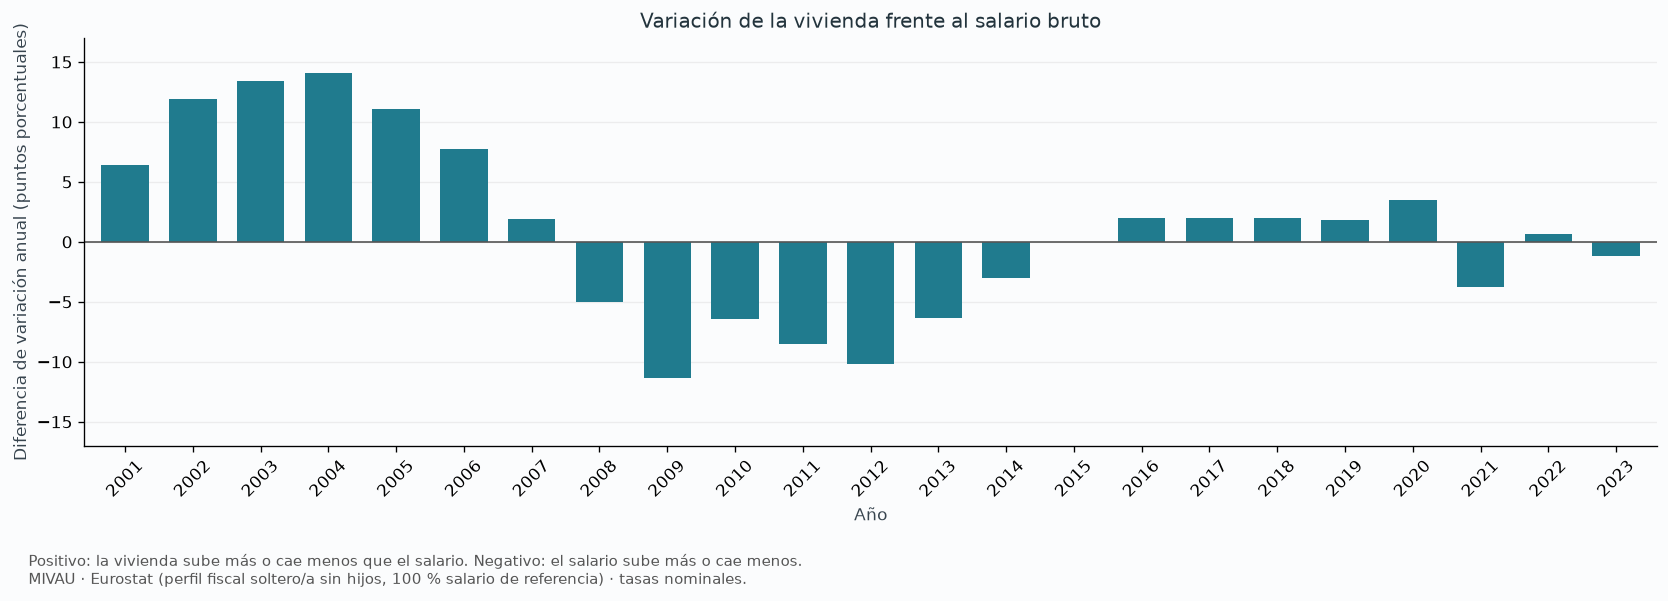

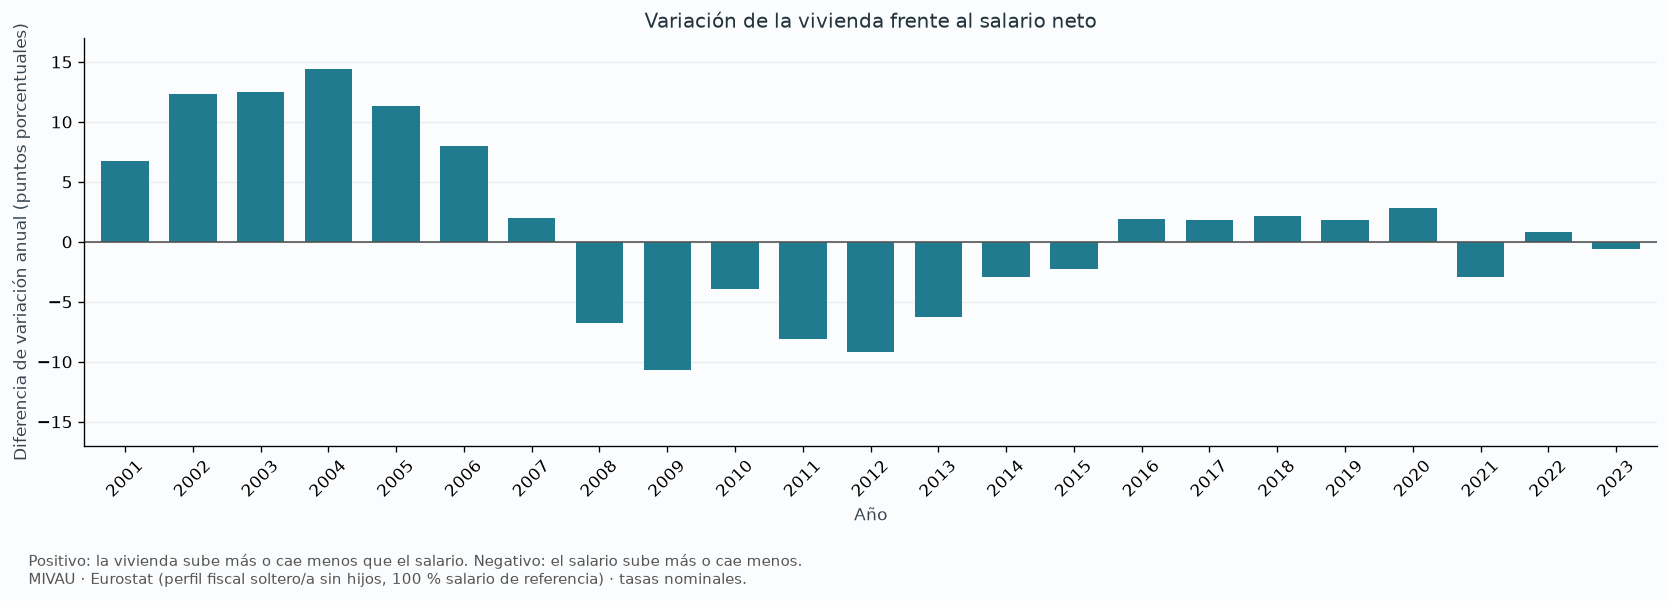

,Vivienda frente a salario bruto,Vivienda frente a salario neto
year,,
2001,6.39,6.78
2002,11.93,12.34
2003,13.40,12.52
2004,14.04,14.42
2005,11.06,11.33
2006,7.73,7.97
2007,1.88,2.03
2008,-5.03,-6.75
2009,-11.36,-10.72


In [17]:
# Las figuras y la tabla se generaron con el mismo módulo de la sección 2.1.
show("18_housing_salary_gross_gap", "19_housing_salary_net_gap")
display(salary_variation_gap.round(2))


## Lectura conjunta

El crecimiento depende del periodo elegido y cambia entre territorios. Las comparaciones con ingresos ayudan a valorar el cambio relativo, pero faltan ingresos del hogar, entrada, gastos e intereses hipotecarios para medir el esfuerzo de compra. Las coincidencias con presidencias no identifican efectos causales.

El siguiente bloque estudia población, hogares y construcción: [Demografía y vivienda](02_demographics.ipynb).